In [1]:
import json
import sys
from pathlib import Path

import torch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from reasoning_from_scratch.qwen3 import (
    QWEN_CONFIG_06_B,
    Qwen3Model,
    Qwen3Tokenizer,
    download_qwen3_small,
)

download_qwen3_small(kind="base", out_dir=ROOT / "qwen3")

tokenizer = Qwen3Tokenizer(ROOT / "qwen3" / "tokenizer-base.json")
model = Qwen3Model(QWEN_CONFIG_06_B)
weights = torch.load(ROOT / "qwen3" / "qwen3-0.6B-base.pth", map_location="cpu", weights_only=True)
model.load_state_dict(weights)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

c:\Portfolio\small-llm-advanced\qwen3\qwen3-0.6B-base.pth already up-to-date
c:\Portfolio\small-llm-advanced\qwen3\tokenizer-base.json already up-to-date


Qwen3Model(
  (tok_emb): Embedding(151936, 1024)
  (trf_blocks): ModuleList(
    (0-27): 28 x TransformerBlock(
      (att): GroupedQueryAttention(
        (W_query): Linear(in_features=1024, out_features=2048, bias=False)
        (W_key): Linear(in_features=1024, out_features=1024, bias=False)
        (W_value): Linear(in_features=1024, out_features=1024, bias=False)
        (out_proj): Linear(in_features=2048, out_features=1024, bias=False)
        (q_norm): RMSNorm()
        (k_norm): RMSNorm()
      )
      (ff): FeedForward(
        (fc1): Linear(in_features=1024, out_features=3072, bias=False)
        (fc2): Linear(in_features=1024, out_features=3072, bias=False)
        (fc3): Linear(in_features=3072, out_features=1024, bias=False)
      )
      (norm1): RMSNorm()
      (norm2): RMSNorm()
    )
  )
  (final_norm): RMSNorm()
  (out_head): Linear(in_features=1024, out_features=151936, bias=False)
)

In [2]:
def generate(model, idx, max_new_tokens, eos_id):
    """Greedy completion. Returns the prompt plus the new tokens."""
    for _ in range(max_new_tokens):
        with torch.inference_mode():
            logits = model(idx)[:, -1, :]
        next_id = torch.argmax(logits, dim=-1, keepdim=True)
        if next_id.item() == eos_id:
            break
        idx = torch.cat((idx, next_id), dim=1)
    return idx


prompt = (
    "Below is an instruction that describes a task. "
    "Write a response that appropriately completes the request.\n\n"
    "### Instruction:\n"
    "What is the capital of France?\n\n"
    "### Response:\n"
)

token_ids = torch.tensor(tokenizer.encode(prompt), device=device).unsqueeze(0)
out_ids = generate(model, token_ids, max_new_tokens=20, eos_id=tokenizer.eos_token_id)
print(tokenizer.decode(out_ids[0].tolist())[len(prompt):])

The capital of France is **Paris**.


In [5]:
def generate(model, idx, max_new_tokens, eos_id, stop_text="\nCliente:"):
    """Greedy completion. Stops at eos or at the next speaker tag."""
    for _ in range(max_new_tokens):
        with torch.inference_mode():
            logits = model(idx)[:, -1, :]
        next_id = torch.argmax(logits, dim=-1, keepdim=True)
        if next_id.item() == eos_id:
            break
        idx = torch.cat((idx, next_id), dim=1)
        if stop_text in tokenizer.decode(idx[0].tolist()):
            break
    return idx


prompt = "Cliente: Dale seguimiento a la orden ORD-89736.\nAsistente:"
token_ids = torch.tensor(tokenizer.encode(prompt), device=device).unsqueeze(0)
out_ids = generate(model, token_ids, max_new_tokens=80, eos_id=tokenizer.eos_token_id)
reply = tokenizer.decode(out_ids[0].tolist())[len(prompt):]
print(reply.split("\nCliente:")[0].strip())

¿Qué tipo de seguimiento se está solicitando?


In [6]:
if not torch.cuda.is_available():
    raise RuntimeError("CUDA is not available.")

device = torch.device("cuda")
model.to(device)
props = torch.cuda.get_device_properties(0)
print(torch.cuda.get_device_name(0), f"{props.total_memory / 1024**3:.1f} GiB")

NVIDIA GeForce RTX 3060 Laptop GPU 6.0 GiB


## How training works

The base model only continues whatever text it is given. Training shows it 816 customer messages, each paired with the shop action it should write after `### Response:`.

The customer message is wrapped with the shop instruction. That instruction is part of the training prompt. The loss does not cover it. Prompt tokens and padding are set to `-100`, and cross-entropy ignores that index, so the update only scores the action. One pad token is left visible: it teaches the model where the action ends.

AdamW on every parameter needs about 9 GiB. This GPU has 6, so the token embedding and the first 24 blocks stay frozen. Gradients update the last 4 blocks, the final norm, and the output head: 218.5M of 751.6M parameters.

The loader feeds one example at a time. Gradients accumulate for 4 steps before AdamW moves the weights, which matches a batch of 4 without holding 4 sequences in memory. The learning rate is `1e-5`. One pass over the training split is enough for the action format to show up. `model.eval()` then switches the same weights over to generation.

In [7]:
from functools import partial
from torch.utils.data import DataLoader, Dataset

INSTRUCTION = (
    "You are a shop assistant for a clothing and shoe store. "
    "Read the customer message and return only the next action as JSON "
    "with keys action, slots, missing, and reply. "
    "Do not invent products, prices, or stock."
)


def format_input(entry: dict) -> str:
    """Format an instruction entry as the training prompt."""
    instruction_text = (
        "Below is an instruction that describes a task. "
        "Write a response that appropriately completes the request."
        f"\n\n### Instruction:\n{entry['instruction']}"
    )
    input_text = f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""
    return instruction_text + input_text


class InstructionDataset(Dataset):
    """Prompt plus response, with the prompt length kept for the loss mask."""

    def __init__(self, data: list[dict], tokenizer) -> None:
        self.examples = []
        for entry in data:
            prompt = format_input(entry) + "\n\n### Response:\n"
            full = prompt + entry["output"]
            prompt_ids = tokenizer.encode(prompt)
            full_ids = tokenizer.encode(full)
            self.examples.append((full_ids, len(prompt_ids)))

    def __getitem__(self, index: int) -> tuple[list[int], int]:
        return self.examples[index]

    def __len__(self) -> int:
        return len(self.examples)


def collate(batch, device, pad_id: int):
    """Pad a batch and ignore prompt and padding tokens in the loss."""
    sequences, prompt_lens = [], []
    for ids, prompt_len in batch:
        sequences.append(ids + [pad_id])
        prompt_lens.append(prompt_len)
    max_len = max(len(seq) for seq in sequences)
    input_rows, target_rows = [], []
    for seq, prompt_len in zip(sequences, prompt_lens):
        padded = seq + [pad_id] * (max_len - len(seq))
        inputs = torch.tensor(padded[:-1], device=device)
        targets = torch.tensor(padded[1:], device=device)
        targets[: prompt_len - 1] = -100
        pad_positions = (targets == pad_id).nonzero(as_tuple=True)[0]
        if len(pad_positions) > 1:
            targets[pad_positions[1:]] = -100
        input_rows.append(inputs)
        target_rows.append(targets)
    return torch.stack(input_rows), torch.stack(target_rows)


for param in model.parameters():
    param.requires_grad = False
for block in model.trf_blocks[-4:]:
    for param in block.parameters():
        param.requires_grad = True
for param in model.final_norm.parameters():
    param.requires_grad = True
for param in model.out_head.parameters():
    param.requires_grad = True

trainable = [param for param in model.parameters() if param.requires_grad]
n_trainable = sum(param.numel() for param in trainable)
n_total = sum(param.numel() for param in model.parameters())
print(f"trainable {n_trainable / 1e6:.1f}M / {n_total / 1e6:.1f}M")

with open(ROOT / "data" / "instruction-data.json", encoding="utf-8") as f:
    data = json.load(f)

train_portion = int(len(data) * 0.85)
test_portion = int(len(data) * 0.1)
train_data = data[:train_portion]
val_data = data[train_portion + test_portion :]

collate_fn = partial(collate, device=device, pad_id=tokenizer.pad_token_id)
train_loader = DataLoader(
    InstructionDataset(train_data, tokenizer),
    batch_size=1,
    collate_fn=collate_fn,
    shuffle=True,
    drop_last=True,
    num_workers=0,
)
print("train", len(train_data), "val", len(val_data), "steps", len(train_loader))

trainable 218.5M / 751.6M
train 816 val 48 steps 816


In [8]:
optimizer = torch.optim.AdamW(trainable, lr=1e-5, weight_decay=0.1)
accum_steps = 4
model.train()
optimizer.zero_grad()

for step, (inputs, targets) in enumerate(train_loader, start=1):
    logits = model(inputs)
    loss = torch.nn.functional.cross_entropy(
        logits.flatten(0, 1).float(),
        targets.flatten(),
    )
    (loss / accum_steps).backward()
    if step % accum_steps == 0 or step == len(train_loader):
        optimizer.step()
        optimizer.zero_grad()
    if step % 20 == 0 or step == len(train_loader):
        print(f"step {step}/{len(train_loader)} loss {loss.item():.3f}")

model.eval()
torch.cuda.empty_cache()

step 20/816 loss 1.110
step 40/816 loss 0.823
step 60/816 loss 0.692
step 80/816 loss 0.690
step 100/816 loss 2.479
step 120/816 loss 0.909
step 140/816 loss 0.761
step 160/816 loss 0.781
step 180/816 loss 0.865
step 200/816 loss 0.582
step 220/816 loss 0.320
step 240/816 loss 0.452
step 260/816 loss 0.709
step 280/816 loss 0.433
step 300/816 loss 1.000
step 320/816 loss 0.367
step 340/816 loss 1.432
step 360/816 loss 0.546
step 380/816 loss 0.292
step 400/816 loss 1.219
step 420/816 loss 0.476
step 440/816 loss 0.644
step 460/816 loss 0.987
step 480/816 loss 0.679
step 500/816 loss 1.360
step 520/816 loss 0.250
step 540/816 loss 0.393
step 560/816 loss 0.673
step 580/816 loss 0.573
step 600/816 loss 0.286
step 620/816 loss 0.578
step 640/816 loss 0.460
step 660/816 loss 0.218
step 680/816 loss 0.518
step 700/816 loss 0.412
step 720/816 loss 0.247
step 740/816 loss 0.380
step 760/816 loss 0.447
step 780/816 loss 0.251
step 800/816 loss 0.449
step 816/816 loss 0.295


In [9]:
prompt = format_input({
    "instruction": INSTRUCTION,
    "input": "Dale seguimiento a la orden ORD-89736",
}) + "\n\n### Response:\n"

token_ids = torch.tensor(tokenizer.encode(prompt), device=device).unsqueeze(0)
out_ids = generate(model, token_ids, max_new_tokens=80, eos_id=tokenizer.eos_token_id)
print(tokenizer.decode(out_ids[0].tolist())[len(prompt):].split("<|endoftext|>")[0].strip())

{"action":"track_order","slots":{"order_id":"ORD-89736"},"missing":[],"reply":"Order tracking."}


In [12]:
def show_before_after(customer: str) -> None:
    """Print a plain base reply, then the finetuned reply."""
    finetuned_path = ROOT / "qwen3" / "shop-finetuned.pth"
    if not finetuned_path.is_file():
        torch.save(model.state_dict(), finetuned_path)

    def complete(weights_path: Path, prompt: str, stop_text: str) -> str:
        weights = torch.load(weights_path, map_location=device, weights_only=True)
        model.load_state_dict(weights)
        model.eval()
        token_ids = torch.tensor(tokenizer.encode(prompt), device=device).unsqueeze(0)
        out_ids = generate(
            model, token_ids, max_new_tokens=80, eos_id=tokenizer.eos_token_id, stop_text=stop_text
        )
        text = tokenizer.decode(out_ids[0].tolist())[len(prompt):]
        return text.split(stop_text)[0].split("<|endoftext|>")[0].strip()

    plain = f"Cliente: {customer}\nAsistente:"
    trained = format_input({"instruction": INSTRUCTION, "input": customer}) + "\n\n### Response:\n"

    print("ANTES")
    print(complete(ROOT / "qwen3" / "qwen3-0.6B-base.pth", plain, "\nCliente:"))
    print("\nDESPUÉS")
    print(complete(finetuned_path, trained, "<|endoftext|>"))


show_before_after("Busco tenis para correr, talla 42, que no sean negros")

ANTES
¿Qué tipo de tenis prefieres?

DESPUÉS
{"action":"search_products","slots":{"category":"running shoes","size":"42","color":"no"},"missing":[],"reply":"Buscando tenis para correr, talla 42."}


## Pictures of the finetune

The pictures below are drawn with matplotlib, so they show up as images in the notebook.

We started from the Qwen3 0.6B base weights: a model that continues text, with every parameter still at its pretrained value. The shop examples never replaced that model. They nudged part of it.

Every example still runs through the whole stack. The embedding and the first 24 blocks keep the base weights and only carry the text forward. The last 4 blocks, the final norm, and the output head are the ones AdamW rewrites.

A training row is the shop instruction, the customer message, and the action that should follow `### Response:`. The loss looks only at that action. Prompt tokens and extra padding are marked `-100`, so they do not pull on the weights. One padding token stays visible and marks the end of the action.

The GPU holds one example at a time. Each example produces a gradient, and four of those gradients are added together before AdamW takes a step. That is a batch of 4 in effect, with the memory of a batch of 1. The learning rate is `1e-5`. After 816 examples, the updated weights are the ones used to generate.

At the end the frozen weights are still the base model. The trained slice is what turns the same kind of customer message into the shop action instead of a free-form reply.


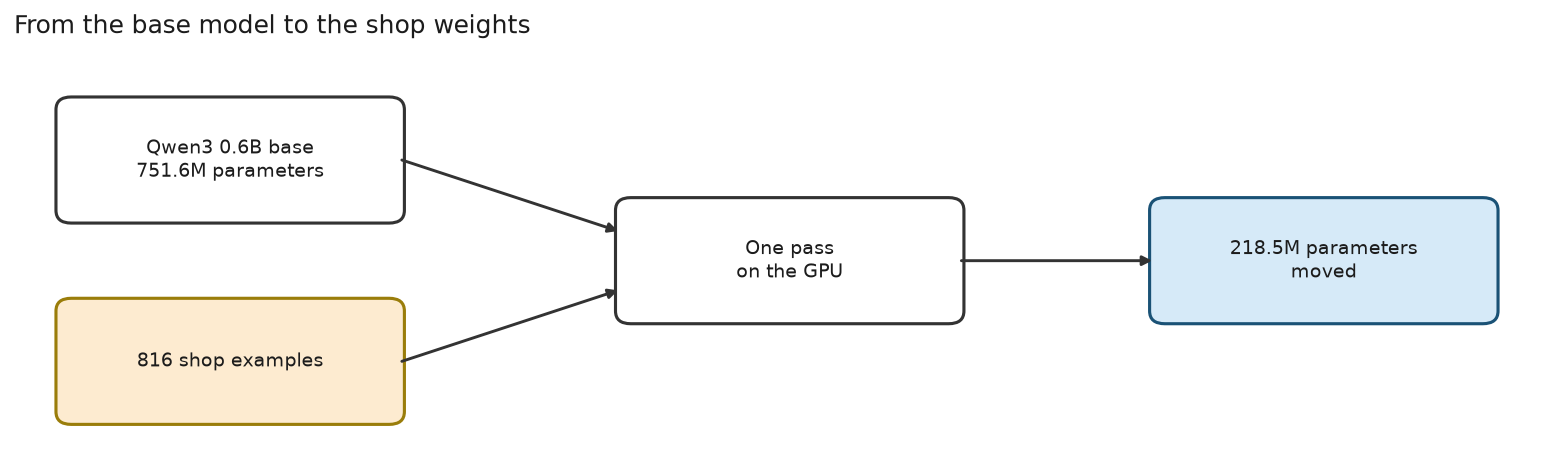

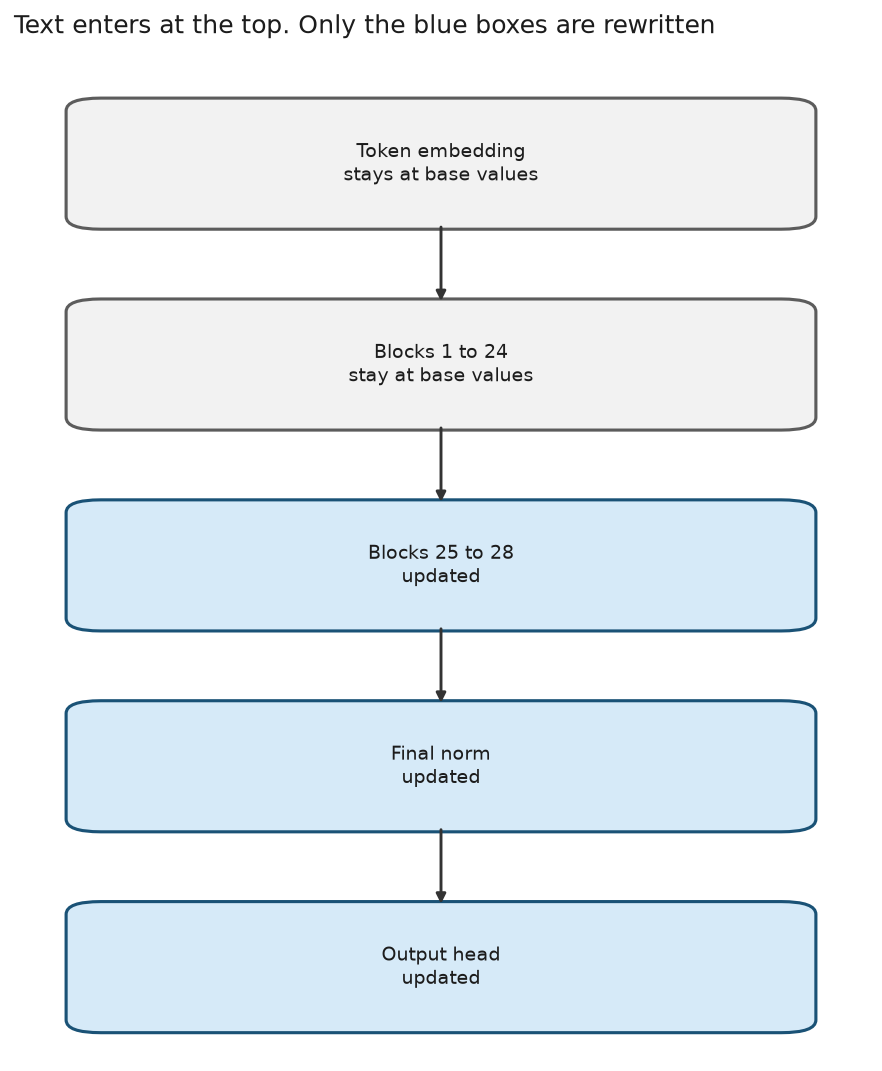

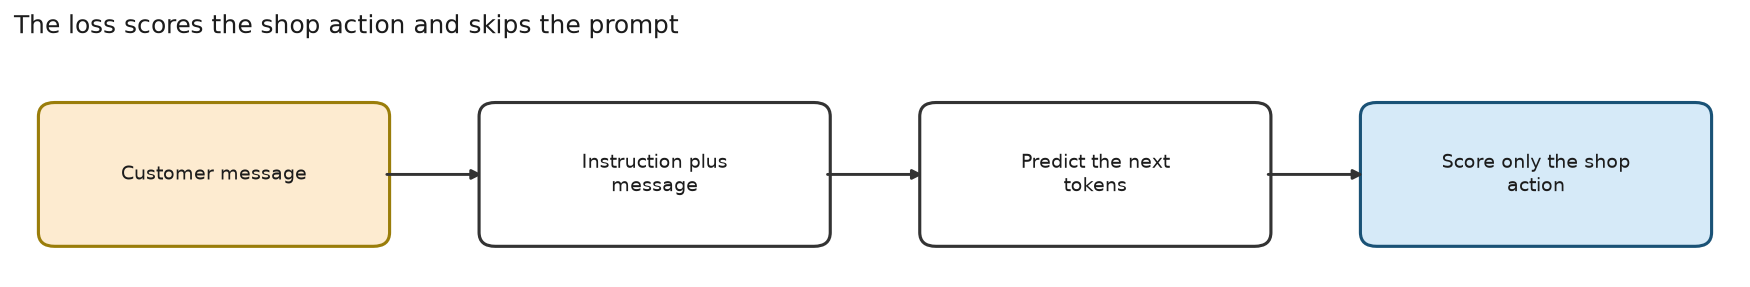

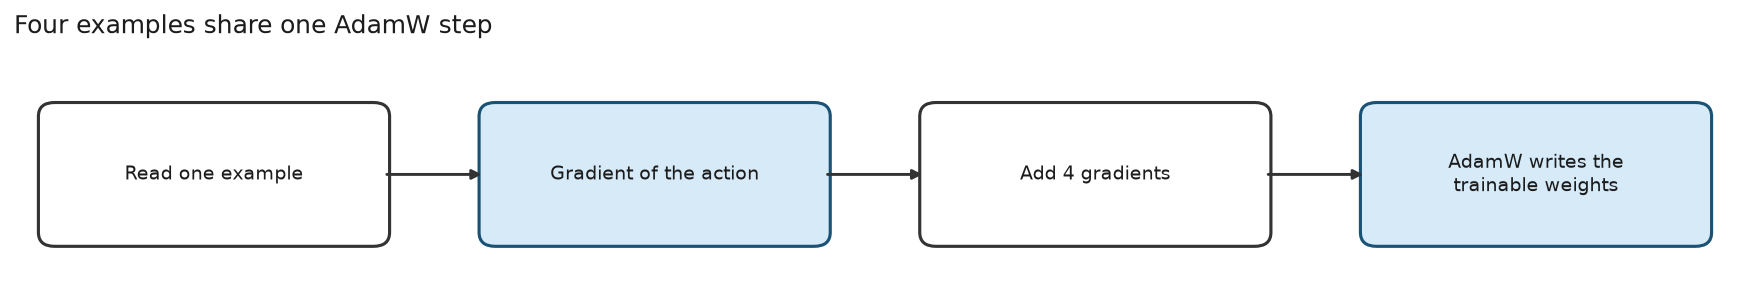

In [1]:
from __future__ import annotations

import textwrap

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

_COLORS = {
    "frozen": ("#F2F2F2", "#5C5C5C"),
    "trained": ("#D6EAF8", "#1A5276"),
    "data": ("#FDEBD0", "#9A7D0A"),
    "plain": ("#FFFFFF", "#333333"),
}


def _label(text: str) -> str:
    """Wrap each line so it fits inside a box."""
    return "\n".join(textwrap.fill(line, 22) for line in text.split("\n"))


def _box(ax, x: float, y: float, text: str, kind: str, width: float = 2.5, height: float = 1.15) -> None:
    """Draw one rounded box with a centered label."""
    face, edge = _COLORS[kind]
    ax.add_patch(
        FancyBboxPatch(
            (x - width / 2, y - height / 2),
            width,
            height,
            boxstyle="round,pad=0.02,rounding_size=0.12",
            facecolor=face,
            edgecolor=edge,
            linewidth=1.6,
        )
    )
    ax.text(x, y, _label(text), ha="center", va="center", fontsize=10, color="#1C1C1C")


def _arrow(ax, start: tuple[float, float], end: tuple[float, float]) -> None:
    """Draw a straight arrow between two points."""
    ax.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops={"arrowstyle": "-|>", "color": "#333333", "lw": 1.5, "shrinkA": 0, "shrinkB": 0},
    )


def draw_flow(title: str, nodes: list[tuple[str, str]], direction: str = "lr") -> plt.Figure:
    """Draw boxes in a row or a column and connect them with arrows."""
    width, height, gap = 2.55, 1.2, 0.7
    count = len(nodes)
    if direction == "lr":
        figure, ax = plt.subplots(figsize=(count * 3.15, 2.15), dpi=140)
        centers = [(index * (width + gap), 0.0) for index in range(count)]
    else:
        figure, ax = plt.subplots(figsize=(6.4, count * 1.55), dpi=140)
        centers = [(0.0, (count - 1 - index) * (height + gap)) for index in range(count)]

    for (x_pos, y_pos), (label, kind) in zip(centers, nodes):
        _box(ax, x_pos, y_pos, label, kind, width, height)

    for (x1, y1), (x2, y2) in zip(centers, centers[1:]):
        if direction == "lr":
            _arrow(ax, (x1 + width / 2, y1), (x2 - width / 2, y2))
        else:
            _arrow(ax, (x1, y1 - height / 2), (x2, y2 + height / 2))

    xs = [center[0] for center in centers]
    ys = [center[1] for center in centers]
    ax.set_xlim(min(xs) - width / 2 - 0.2, max(xs) + width / 2 + 0.2)
    ax.set_ylim(min(ys) - height / 2 - 0.25, max(ys) + height / 2 + 0.45)
    ax.set_axis_off()
    ax.set_title(title, fontsize=13, loc="left", color="#1C1C1C", pad=10)
    figure.tight_layout()
    return figure


def draw_overview() -> plt.Figure:
    """Show the base model and the shop examples meeting in one GPU pass."""
    figure, ax = plt.subplots(figsize=(11.2, 3.5), dpi=140)
    width, height = 2.7, 1.15
    spots = {
        "base": (0.0, 0.95, "Qwen3 0.6B base\n751.6M parameters", "plain"),
        "data": (0.0, -0.95, "816 shop examples", "data"),
        "step": (4.4, 0.0, "One pass\non the GPU", "plain"),
        "tuned": (8.6, 0.0, "218.5M parameters\nmoved", "trained"),
    }
    for x_pos, y_pos, label, kind in spots.values():
        _box(ax, x_pos, y_pos, label, kind, width, height)
    _arrow(ax, (width / 2, 0.95), (4.4 - width / 2, 0.28))
    _arrow(ax, (width / 2, -0.95), (4.4 - width / 2, -0.28))
    _arrow(ax, (4.4 + width / 2, 0.0), (8.6 - width / 2, 0.0))
    ax.set_xlim(-1.7, 10.3)
    ax.set_ylim(-1.9, 2.0)
    ax.set_axis_off()
    ax.set_title("From the base model to the shop weights", fontsize=13, loc="left", color="#1C1C1C", pad=8)
    figure.tight_layout()
    return figure


FIGURES = [
    draw_overview(),
    draw_flow(
        "Text enters at the top. Only the blue boxes are rewritten",
        [
            ("Token embedding\nstays at base values", "frozen"),
            ("Blocks 1 to 24\nstay at base values", "frozen"),
            ("Blocks 25 to 28\nupdated", "trained"),
            ("Final norm\nupdated", "trained"),
            ("Output head\nupdated", "trained"),
        ],
        direction="tb",
    ),
    draw_flow(
        "The loss scores the shop action and skips the prompt",
        [
            ("Customer message", "data"),
            ("Instruction plus message", "plain"),
            ("Predict the next tokens", "plain"),
            ("Score only the shop action", "trained"),
        ],
    ),
    draw_flow(
        "Four examples share one AdamW step",
        [
            ("Read one example", "plain"),
            ("Gradient of the action", "trained"),
            ("Add 4 gradients", "plain"),
            ("AdamW writes the trainable weights", "trained"),
        ],
    ),
]

for figure in FIGURES:
    figure.patch.set_facecolor("white")
    display(figure)
